In [3]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "/home/pooja/TATRO/TATRO_Program_files/TATARO_FirmwareV1.0/xarm_ros2/MOCAP_Validation/sync_marker_charuco_log_20260708_162243.csv"

In [4]:
df = pd.read_csv(CSV_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%Y-%m-%d %H:%M:%S.%f")
df.head()

,Timestamp,Sync_Data,User_Marker,Charuco_Valid,Charuco_X,Charuco_Y,Charuco_Z,Charuco_QX,Charuco_QY,Charuco_QZ,Charuco_QW,Charuco_RX,Charuco_RY,Charuco_RZ
0,2026-07-08 16:22:43.852,0,0,0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2026-07-08 16:22:43.863,0,0,0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,2026-07-08 16:22:43.873,0,0,1,-0.015468,-0.01554,0.771269,-0.304299,0.216066,0.641473,0.670246,-0.685779,0.486934,1.445648
3,2026-07-08 16:22:43.883,0,0,1,-0.015468,-0.01554,0.771269,-0.304299,0.216066,0.641473,0.670246,-0.685779,0.486934,1.445648
4,2026-07-08 16:22:43.893,0,0,1,-0.015468,-0.01554,0.771269,-0.304299,0.216066,0.641473,0.670246,-0.685779,0.486934,1.445648


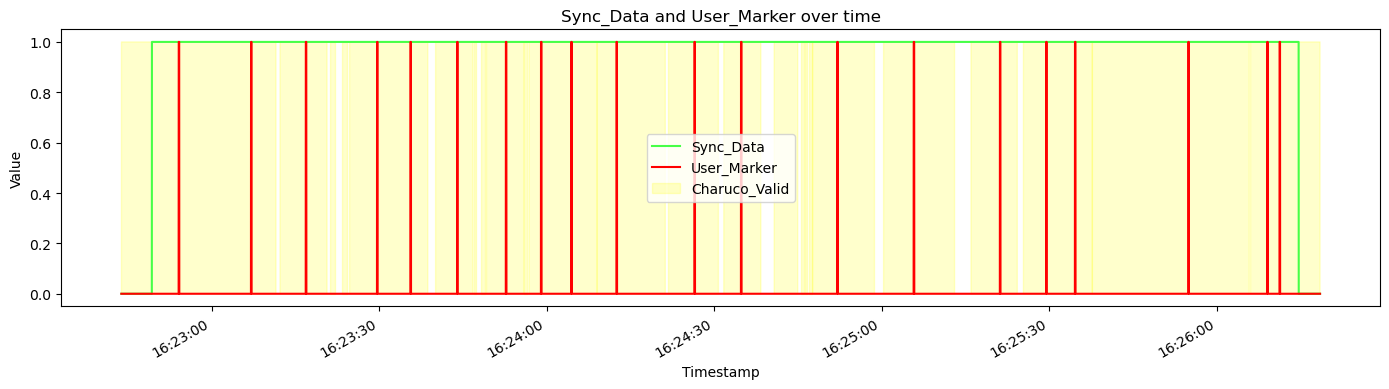

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))

# .to_numpy() avoids a pandas/matplotlib datetime-indexing incompatibility
# on older matplotlib versions.
ax.plot(df["Timestamp"].to_numpy(), df["Sync_Data"].to_numpy(), color="#47FF47", label="Sync_Data")
ax.plot(df["Timestamp"].to_numpy(), df["User_Marker"].to_numpy(), color="red", label="User_Marker")

# Shade the periods where the ChArUco board was detected, rather than
# plotting Charuco_Valid as a 0/1 line on top of the other signals.
charuco_valid = df["Charuco_Valid"].to_numpy().astype(bool)
ax.fill_between(df["Timestamp"].to_numpy(), 0, 1, where=charuco_valid,
                 step="mid", color="yellow", alpha=0.2, label="Charuco_Valid")

ax.set_xlabel("Timestamp")
ax.set_ylabel("Value")
ax.set_title("Sync_Data and User_Marker over time")
ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

In [6]:
import re
import csv


OPTITRACK_CSV_PATH = "trial2_02.csv"
LOGGER_CSV_PATH = "sync_marker_charuco_log_20260708_162243.csv"
ALIGNED_OUTPUT_PATH = "trial2_02_aligned_dataset.csv"


def _sanitize(name: str) -> str:
    """Collapse anything that isn't alphanumeric/underscore into a single '_'."""
    return re.sub(r"[^0-9A-Za-z]+", "_", name).strip("_")


def locate_motive_header_rows(path: str):
    """
    Locate the Type / Name / ID / Sub-type / Axis header rows of a Motive
    export by searching for the row whose second cell reads "Type", rather
    than assuming a fixed row number. This keeps the parser working even if
    the take-metadata block above it changes size.

    Returns (name_row, subtype_row, axis_row, data_start_line).
    """
    with open(path, newline="") as f:
        reader = csv.reader(f)
        rows = [row for row, _ in zip(reader, range(20))]  # header block is always small

    type_row_idx = next(i for i, row in enumerate(rows) if len(row) > 1 and row[1] == "Type")
    name_row_idx = type_row_idx + 1
    # id_row_idx = type_row_idx + 2  # asset GUID / marker ID -- not needed for flattening
    subtype_row_idx = type_row_idx + 3
    axis_row_idx = type_row_idx + 4

    name_row = rows[name_row_idx]
    subtype_row = rows[subtype_row_idx]
    axis_row = rows[axis_row_idx]
    data_start_line = axis_row_idx + 1
    return name_row, subtype_row, axis_row, data_start_line


def flatten_motive_columns(name_row, subtype_row, axis_row):

    seen = {}
    flat_names = []
    for i, (name, subtype, axis) in enumerate(zip(name_row, subtype_row, axis_row)):
        if i < 2:
            parts = [axis.strip()]
        else:
            parts = [p.strip() for p in (name, subtype, axis) if p and p.strip()]
        col = _sanitize("_".join(parts))

        if col in seen:
            seen[col] += 1
            col = f"{col}_{seen[col]}"
        else:
            seen[col] = 1
        flat_names.append(col)
    return flat_names


def load_optitrack(path: str) -> pd.DataFrame:
    """Read a Motive export CSV, flattening its MultiIndex header into
    single-level column names, without altering any pose values."""
    name_row, subtype_row, axis_row, data_start_line = locate_motive_header_rows(path)
    flat_names = flatten_motive_columns(name_row, subtype_row, axis_row)
    return pd.read_csv(path, skiprows=data_start_line, header=None, names=flat_names)


def load_logger(path: str) -> pd.DataFrame:
    """Read the sync-marker logger CSV and parse its Timestamp column."""
    logger_df = pd.read_csv(path)
    logger_df["Timestamp"] = pd.to_datetime(logger_df["Timestamp"], format="%Y-%m-%d %H:%M:%S.%f")
    return logger_df


def extract_sync_segment(logger_df: pd.DataFrame) -> pd.DataFrame:
    """Return the contiguous logger rows where Sync_Data == 1, i.e. the
    MoCap recording window."""
    return logger_df[logger_df["Sync_Data"] == 1].reset_index(drop=True)


def synchronize(opti_df: pd.DataFrame, sync_segment: pd.DataFrame) -> pd.DataFrame:
    """
    Align OptiTrack and logger samples index-for-index. No interpolation or
    resampling: if the two recordings differ by a few samples (start/stop
    jitter), both are simply trimmed to their common length before being
    concatenated column-wise.

    Carries Sync_Data/User_Marker plus any Charuco_* columns present in the
    logger (older sync_marker_log_*.csv files don't have them - only the
    newer sync_marker_charuco_log_*.csv ones, like this trial's, do).
    """
    min_len = min(len(opti_df), len(sync_segment))
    opti_trim = opti_df.iloc[:min_len].reset_index(drop=True)
    logger_trim = sync_segment.iloc[:min_len].reset_index(drop=True)

    logger_cols = ["Timestamp", "Sync_Data", "User_Marker"]
    logger_cols += [c for c in logger_trim.columns if c.startswith("Charuco_")]

    return pd.concat(
        [logger_trim[logger_cols], opti_trim],
        axis=1,
    )


# ------------------------------------ Run ----------------------------------

optitrack_df = load_optitrack(OPTITRACK_CSV_PATH)
logger_df = load_logger(LOGGER_CSV_PATH)
sync_segment_df = extract_sync_segment(logger_df)
aligned_df = synchronize(optitrack_df, sync_segment_df)
aligned_df.to_csv(ALIGNED_OUTPUT_PATH, index=False)

length_mismatch = abs(len(optitrack_df) - len(sync_segment_df))
sync_ok = len(aligned_df) > 0 and length_mismatch / max(len(optitrack_df), 1) < 0.05

print(f"Total OptiTrack samples:            {len(optitrack_df)}")
print(f"Total logger samples:               {len(logger_df)}")
print(f"Logger samples with Sync_Data == 1: {len(sync_segment_df)}")
print(f"Synchronized samples (saved):       {len(aligned_df)}")
print(f"Length mismatch (Opti vs Sync==1):  {length_mismatch}")
print(f"Synchronization successful:         {sync_ok}")
print(f"Wrote {len(aligned_df)} rows -> {ALIGNED_OUTPUT_PATH}")


Total OptiTrack samples:            20524
Total logger samples:               21469
Logger samples with Sync_Data == 1: 20538
Synchronized samples (saved):       20524
Length mismatch (Opti vs Sync==1):  14
Synchronization successful:         True
Wrote 20524 rows -> trial2_02_aligned_dataset.csv


In [7]:
import numpy as np

# Group consecutive User_Marker == 1 rows into distinct calibration events
# (each 'S' key press holds the marker for a fixed number of samples), and
# check how many samples per event had a valid ChArUco detection.
marker_idx = np.flatnonzero((aligned_df["User_Marker"] == 1).to_numpy())
event_groups = []
run = [marker_idx[0]]
for i in marker_idx[1:]:
    if i == run[-1] + 1:
        run.append(i)
    else:
        event_groups.append(run)
        run = [i]
event_groups.append(run)

event_rows = []
for event_id, idx in enumerate(event_groups):
    group = aligned_df.loc[idx]
    num_samples = len(group)
    num_valid = int(group["Charuco_Valid"].sum())
    event_rows.append({
        "event_id": event_id,
        "num_samples": num_samples,
        "num_charuco_valid": num_valid,
        "all_valid": num_valid == num_samples,
    })

event_validity_df = pd.DataFrame(event_rows)
total_samples = int(event_validity_df["num_samples"].sum())
total_valid = int(event_validity_df["num_charuco_valid"].sum())

print(f"Events found:                        {len(event_validity_df)}")
print(f"Total marked samples:                {total_samples}")
print(f"Charuco_Valid among marked samples:  {total_valid} ({total_valid/total_samples*100:.2f}%)")
print(f"Events fully Charuco-valid:          {int(event_validity_df['all_valid'].sum())} / {len(event_validity_df)}")

event_validity_df


Events found:                        20
Total marked samples:                200
Charuco_Valid among marked samples:  200 (100.00%)
Events fully Charuco-valid:          20 / 20


,event_id,num_samples,num_charuco_valid,all_valid
0,0,10,10,True
1,1,10,10,True
2,2,10,10,True
3,3,10,10,True
4,4,10,10,True
5,5,10,10,True
6,6,10,10,True
7,7,10,10,True
8,8,10,10,True
9,9,10,10,True


In [8]:
from scipy.spatial.transform import Rotation

OUTPUT_PATH = "trial2_02_valid_marked_frames.csv"

CHARUCO_COLS = [
    "Charuco_Valid",
    "Charuco_X", "Charuco_Y", "Charuco_Z",
    "Charuco_QX", "Charuco_QY", "Charuco_QZ", "Charuco_QW",
    "Charuco_RX", "Charuco_RY", "Charuco_RZ",
]
# TableMarker position comes from the raw "TableMarker:Marker1" physical
# marker rather than the rigid body's tracked centroid position. Orientation
# is built from the Marker1/2/3 triangle (X: 1->2, Y: 1->3, Z: X cross Y)
# instead of the rigid body's tracked quaternion - see marker_frame_quaternion
# below.
OPTITRACK_COLS = [
    "TableMarker_Marker1_Position_X", "TableMarker_Marker1_Position_Y", "TableMarker_Marker1_Position_Z",
    "TableMarker_Marker2_Position_X", "TableMarker_Marker2_Position_Y", "TableMarker_Marker2_Position_Z",
    "TableMarker_Marker3_Position_X", "TableMarker_Marker3_Position_Y", "TableMarker_Marker3_Position_Z",
    "LinkCamera_Position_X", "LinkCamera_Position_Y", "LinkCamera_Position_Z",
    "LinkCamera_Rotation_X", "LinkCamera_Rotation_Y", "LinkCamera_Rotation_Z", "LinkCamera_Rotation_W",
]
KEEP_COLS = ["Timestamp", "Sync_Data", "User_Marker"] + CHARUCO_COLS + OPTITRACK_COLS

# Marked event frames (User_Marker == 1) that also had a valid ChArUco
# detection - the frames trustworthy for downstream calibration/validation -
# alongside the OptiTrack ground-truth pose of the board (TableMarker) and
# the camera (LinkCamera) for the same frames.
valid_marked_df = aligned_df[
    (aligned_df["User_Marker"] == 1) & (aligned_df["Charuco_Valid"] == 1)
][KEEP_COLS].reset_index(drop=True)


def marker_frame_quaternion(p1, p2, p3):
    """Build a right-handed frame from three TableMarker positions - X axis
    along p1->p2, Y axis along p1->p3, Z axis as X cross Y - and return it
    as an xyzw quaternion. This assumes the physical marker jig places
    Marker1/2/3 in a near right angle, so (X, Y, Z) is already close to
    orthonormal; scipy snaps any residual error to the nearest proper
    rotation matrix.
    """
    x_axis = p2 - p1
    x_axis = x_axis / np.linalg.norm(x_axis, axis=-1, keepdims=True)
    y_axis = p3 - p1
    y_axis = y_axis / np.linalg.norm(y_axis, axis=-1, keepdims=True)
    z_axis = np.cross(x_axis, y_axis)
    z_axis = z_axis / np.linalg.norm(z_axis, axis=-1, keepdims=True)

    rot_matrices = np.stack([x_axis, y_axis, z_axis], axis=-1)
    return Rotation.from_matrix(rot_matrices).as_quat()


p1 = valid_marked_df[[f"TableMarker_Marker1_Position_{a}" for a in "XYZ"]].to_numpy()
p2 = valid_marked_df[[f"TableMarker_Marker2_Position_{a}" for a in "XYZ"]].to_numpy()
p3 = valid_marked_df[[f"TableMarker_Marker3_Position_{a}" for a in "XYZ"]].to_numpy()

# Sanity check: the frame above is only exactly orthonormal if Marker1->2 is
# perpendicular to Marker1->3 on the physical jig - report how far off that
# is in practice.
x_check = (p2 - p1) / np.linalg.norm(p2 - p1, axis=-1, keepdims=True)
y_check = (p3 - p1) / np.linalg.norm(p3 - p1, axis=-1, keepdims=True)
max_perp_error_deg = np.degrees(np.arcsin(np.abs((x_check * y_check).sum(axis=-1)))).max()
print(f"Max deviation from perpendicular, Marker1->2 vs Marker1->3: {max_perp_error_deg:.3f} deg")

quats = marker_frame_quaternion(p1, p2, p3)
valid_marked_df[["TableMarker_Rotation_X", "TableMarker_Rotation_Y", "TableMarker_Rotation_Z", "TableMarker_Rotation_W"]] = quats

# Rename so downstream cells can keep referring to "TableMarker_Position_*"
# regardless of which position source feeds it, and drop the Marker2/3
# positions now that they've been folded into the rotation above.
valid_marked_df = valid_marked_df.rename(columns={
    "TableMarker_Marker1_Position_X": "TableMarker_Position_X",
    "TableMarker_Marker1_Position_Y": "TableMarker_Position_Y",
    "TableMarker_Marker1_Position_Z": "TableMarker_Position_Z",
})
valid_marked_df = valid_marked_df.drop(columns=[
    "TableMarker_Marker2_Position_X", "TableMarker_Marker2_Position_Y", "TableMarker_Marker2_Position_Z",
    "TableMarker_Marker3_Position_X", "TableMarker_Marker3_Position_Y", "TableMarker_Marker3_Position_Z",
])

valid_marked_df.to_csv(OUTPUT_PATH, index=False)

print(f"Wrote {len(valid_marked_df)} rows -> {OUTPUT_PATH}")
valid_marked_df.head(12)


Max deviation from perpendicular, Marker1->2 vs Marker1->3: 0.011 deg
Wrote 200 rows -> trial2_02_valid_marked_frames.csv


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


,Timestamp,Sync_Data,User_Marker,Charuco_Valid,Charuco_X,Charuco_Y,Charuco_Z,Charuco_QX,Charuco_QY,Charuco_QZ,...,LinkCamera_Position_Y,LinkCamera_Position_Z,LinkCamera_Rotation_X,LinkCamera_Rotation_Y,LinkCamera_Rotation_Z,LinkCamera_Rotation_W,TableMarker_Rotation_X,TableMarker_Rotation_Y,TableMarker_Rotation_Z,TableMarker_Rotation_W
0,2026-07-08 16:22:54.123,1,1,1,-0.015706,-0.015857,0.773999,-0.303257,0.216962,0.640293,...,0.457550,-0.414374,-0.057318,-0.298123,0.111840,-0.946218,0.574815,0.326122,-0.246253,0.708937
1,2026-07-08 16:22:54.133,1,1,1,-0.015706,-0.015857,0.773999,-0.303257,0.216962,0.640293,...,0.457384,-0.414180,-0.046419,-0.297181,0.124555,-0.945524,0.574214,0.326925,-0.246214,0.709068
2,2026-07-08 16:22:54.143,1,1,1,-0.015706,-0.015857,0.773999,-0.303257,0.216962,0.640293,...,0.457522,-0.414229,-0.048181,-0.296866,0.124171,-0.945585,0.573034,0.326583,-0.246088,0.710222
3,2026-07-08 16:22:54.153,1,1,1,-0.015706,-0.015857,0.773999,-0.303257,0.216962,0.640293,...,0.457546,-0.414253,-0.048550,-0.296781,0.123848,-0.945635,0.572923,0.326928,-0.246054,0.710165
4,2026-07-08 16:22:54.163,1,1,1,-0.015398,-0.015643,0.776136,-0.299872,0.223890,0.641840,...,0.457542,-0.414241,-0.048440,-0.296773,0.123852,-0.945643,0.572853,0.326885,-0.246076,0.710233
5,2026-07-08 16:22:54.173,1,1,1,-0.015398,-0.015643,0.776136,-0.299872,0.223890,0.641840,...,0.457397,-0.414213,-0.045901,-0.296891,0.125300,-0.945542,0.572901,0.326874,-0.246067,0.710203
6,2026-07-08 16:22:54.183,1,1,1,-0.014446,-0.016412,0.775834,-0.288795,0.225118,0.645968,...,0.457553,-0.414277,-0.047980,-0.296481,0.124482,-0.945675,0.572315,0.326723,-0.245983,0.710774
7,2026-07-08 16:22:54.193,1,1,1,-0.014446,-0.016412,0.775834,-0.288795,0.225118,0.645968,...,0.457321,-0.414260,-0.044599,-0.294677,0.132289,-0.945344,0.572406,0.326652,-0.246015,0.710723
8,2026-07-08 16:22:54.203,1,1,1,-0.015645,-0.015925,0.774593,-0.302381,0.215308,0.640881,...,0.457280,-0.414276,-0.042497,-0.294429,0.134271,-0.945239,0.572440,0.326636,-0.246019,0.710701
9,2026-07-08 16:22:54.213,1,1,1,-0.015645,-0.015925,0.774593,-0.302381,0.215308,0.640881,...,0.457303,-0.414291,-0.042778,-0.294314,0.134369,-0.945248,0.572351,0.326898,-0.245477,0.710839


In [9]:
NUM_SAMPLES_PER_EVENT = 10

LINK_POS_COLS = [f"LinkCamera_Position_{a}" for a in "XYZ"]
LINK_QUAT_COLS = [f"LinkCamera_Rotation_{a}" for a in "XYZW"]
TABLE_POS_COLS = [f"TableMarker_Position_{a}" for a in "XYZ"]
TABLE_QUAT_COLS = [f"TableMarker_Rotation_{a}" for a in "XYZW"]
CHARUCO_POS_COLS = ["Charuco_X", "Charuco_Y", "Charuco_Z"]
CHARUCO_QUAT_COLS = ["Charuco_QX", "Charuco_QY", "Charuco_QZ", "Charuco_QW"]


def average_pose(event_df, pos_cols, quat_cols):
    """Mean position + chordal-L2 mean orientation (scipy's Rotation.mean,
    Markley's method) over the samples of a single event."""
    mean_pos = event_df[pos_cols].to_numpy().mean(axis=0)
    mean_quat = Rotation.from_quat(event_df[quat_cols].to_numpy()).mean().as_quat()
    return mean_pos, mean_quat


# valid_marked_df is already exactly 20 contiguous 10-sample blocks (verified
# above: 20/20 events fully Charuco-valid), so integer-divide the row index
# rather than re-deriving event boundaries from User_Marker.
event_id = np.arange(len(valid_marked_df)) // NUM_SAMPLES_PER_EVENT

event_rows = []
for eid, event_df in valid_marked_df.groupby(event_id):
    link_pos, link_quat = average_pose(event_df, LINK_POS_COLS, LINK_QUAT_COLS)
    table_pos, table_quat = average_pose(event_df, TABLE_POS_COLS, TABLE_QUAT_COLS)
    charuco_pos, charuco_quat = average_pose(event_df, CHARUCO_POS_COLS, CHARUCO_QUAT_COLS)
    event_rows.append({
        "event_id": eid,
        "LinkCamera_Position": link_pos, "LinkCamera_Quat": link_quat,
        "TableMarker_Position": table_pos, "TableMarker_Quat": table_quat,
        "Charuco_Position": charuco_pos, "Charuco_Quat": charuco_quat,
    })

event_pose_df = pd.DataFrame(event_rows)
event_pose_df

,event_id,LinkCamera_Position,LinkCamera_Quat,TableMarker_Position,TableMarker_Quat,Charuco_Position,Charuco_Quat
0,0,"[-0.14186650000000003, 0.45743980000000006, -0...","[0.04726754367349283, 0.2962600237796639, -0.1...","[-0.4693803, -0.12014690000000001, 0.0236784]","[0.5730254593610392, 0.32672293722374957, -0.2...","[-0.015380178425440441, -0.015938683335278758,...","[0.2995204203162155, -0.21965367982283646, -0...."
1,1,"[-0.1603812, 0.44091779999999997, -0.444981699...","[0.19647238888396928, -0.061264796533335164, -...","[-0.4695022, -0.11969460000000001, 0.0233801]","[0.5717983436205606, 0.32573811500397487, -0.2...","[0.09794329279241261, -0.036573314247159774, 0...","[0.13629421166525382, -0.3601084480091501, -0...."
2,2,"[-0.1139146, 0.45098220000000006, -0.3945942]","[0.24799479184662507, 0.47009178454138445, -0....","[-0.4694940000000001, -0.11970049999999999, 0....","[0.5718729754894962, 0.3257678174158345, -0.24...","[-0.09780154071903155, -0.07209081075341256, 0...","[0.4106695724341105, -0.04918180029493602, -0...."
3,3,"[0.0303653, 0.3771379, -0.22585960000000002]","[0.21058347358488966, 0.3420257570704708, -0.2...","[-0.46955660000000005, -0.11939659999999999, 0...","[0.5725105795436644, 0.3252846283809293, -0.24...","[0.0262177346809719, 0.043245644414057274, 0.7...","[0.46274926131835936, -0.08934357008054905, -0..."
4,4,"[0.0596615, 0.35323950000000004, -0.2098808]","[0.34562261372125175, 0.5049452201131055, -0.3...","[-0.4695213, -0.1196476, 0.0234093]","[0.5720534413188828, 0.3256685905888138, -0.24...","[0.048630407062097855, 0.02803720618525255, 0....","[0.46490804365678784, 0.03974412806365368, -0...."
5,5,"[-0.0054156, 0.40167659999999994, -0.297567]","[-0.011454961651764354, -0.28620180198550005, ...","[-0.4695957, -0.11935339999999998, 0.023431900...","[0.5725863411454061, 0.32555993771085445, -0.2...","[0.1978935456593815, -0.14631791182404594, 0.7...","[0.24708794809171028, -0.2227126481491487, -0...."
6,6,"[-0.0798634, 0.4631621, -0.4498942]","[0.03883170223516731, -0.2166550124476626, 0.0...","[-0.46949289999999994, -0.11972069999999999, 0...","[0.5717506333453191, 0.32590351153747066, -0.2...","[0.03398152766669365, -0.043555484366751926, 0...","[-0.2645647750530277, 0.2618345930906144, 0.56..."
7,7,"[-0.0495403, 0.4714834, -0.4218532]","[0.12523985240755903, 0.4209526339513959, -0.2...","[-0.46949869999999994, -0.119716, 0.0233726]","[0.5717490553209352, 0.3258979479047063, -0.24...","[0.01844418326117312, 0.00696346892894822, 0.8...","[0.3775559940683783, -0.15395060351777123, -0...."
8,8,"[-0.0066498, 0.44940009999999997, -0.4099507]","[0.28485415315109014, 0.6081220266969004, -0.3...","[-0.469504, -0.11974850000000001, 0.0233785]","[0.5717287176199437, 0.32605346742279784, -0.2...","[0.060298629794420425, 0.00060848801411642, 0....","[0.4009660883860463, -0.01832153445570417, -0...."
9,9,"[-0.0847185, 0.47149399999999997, -0.456913199...","[0.03336641623822964, -0.18667449103236344, 0....","[-0.46953100000000003, -0.1198297, 0.023421599...","[0.5715079190346142, 0.32651281496905304, -0.2...","[-0.019156018411517435, 0.047526093739836114, ...","[0.3183052739812527, -0.2763444295498739, -0.5..."


In [10]:
def pose_to_H(position, quat):
    """xyz position + xyzw quaternion -> 4x4 homogeneous transform."""
    H = np.eye(4)
    H[:3, :3] = Rotation.from_quat(quat).as_matrix()
    H[:3, 3] = position
    return H


def relative_H(H_list):
    """Consecutive-frame deltas: H_i^-1 @ H_(i+1) for each adjacent pair."""
    return [np.linalg.inv(H_list[i]) @ H_list[i + 1] for i in range(len(H_list) - 1)]


def rotation_angle_deg(H):
    return np.degrees(Rotation.from_matrix(H[:3, :3]).magnitude())


H_W_L = [pose_to_H(r.LinkCamera_Position, r.LinkCamera_Quat) for r in event_pose_df.itertuples()]
H_W_T = [pose_to_H(r.TableMarker_Position, r.TableMarker_Quat) for r in event_pose_df.itertuples()]
H_C_Ch = [pose_to_H(r.Charuco_Position, r.Charuco_Quat) for r in event_pose_df.itertuples()]

# LinkCamera and TableMarker poses are both in the OptiTrack world frame, so
# their relative pose is recovered by chaining through it.
H_L_T = [np.linalg.inv(h_l) @ h_t for h_l, h_t in zip(H_W_L, H_W_T)]

dH_L_T = relative_H(H_L_T)
dH_C_Ch = relative_H(H_C_Ch)

# LinkCamera<->Camera and TableMarker<->ChArUco are each offset by a fixed,
# unknown extrinsic, so dH_L_T and dH_C_Ch are conjugate (similarity)
# transforms of one another rather than numerically identical - conjugation
# preserves rotation angle (not axis), so that's the comparable quantity.
ROTATION_MATCH_THRESHOLD_DEG = 2.0

comparison_df = pd.DataFrame({
    "event_pair": [f"{i}->{i + 1}" for i in range(len(dH_L_T))],
    "angle_L_T_deg": [rotation_angle_deg(h) for h in dH_L_T],
    "angle_C_Ch_deg": [rotation_angle_deg(h) for h in dH_C_Ch],
})
comparison_df["angle_diff_deg"] = (comparison_df["angle_L_T_deg"] - comparison_df["angle_C_Ch_deg"]).abs()
comparison_df["rotations_match"] = comparison_df["angle_diff_deg"] < ROTATION_MATCH_THRESHOLD_DEG

print(f"Mean |angle_L_T - angle_C_Ch|: {comparison_df['angle_diff_deg'].mean():.3f} deg")
print(f"Max  |angle_L_T - angle_C_Ch|: {comparison_df['angle_diff_deg'].max():.3f} deg")
print(f"Matching within {ROTATION_MATCH_THRESHOLD_DEG} deg: "
      f"{int(comparison_df['rotations_match'].sum())} / {len(comparison_df)} event pairs")

comparison_df

Mean |angle_L_T - angle_C_Ch|: 0.614 deg
Max  |angle_L_T - angle_C_Ch|: 1.732 deg
Matching within 2.0 deg: 19 / 19 event pairs


,event_pair,angle_L_T_deg,angle_C_Ch_deg,angle_diff_deg,rotations_match
0,0->1,43.652825,43.142298,0.510527,True
1,1->2,82.101178,81.912809,0.188369,True
2,2->3,17.248022,17.070815,0.177206,True
3,3->4,30.337568,30.616775,0.279207,True
4,4->5,61.869846,61.769856,0.099990,True
5,5->6,10.040494,9.473508,0.566986,True
6,6->7,38.031249,37.380340,0.650909,True
7,7->8,38.247111,37.890096,0.357015,True
8,8->9,75.241460,75.755445,0.513985,True
9,9->10,19.389385,19.532032,0.142648,True


In [11]:
# Inverse-direction transforms - ChArUco -> Camera and TableMarker -> LinkCamera
# - plus their consecutive-frame relative transforms.
H_Ch_C = [np.linalg.inv(h) for h in H_C_Ch]
H_T_L = [np.linalg.inv(h) for h in H_L_T]

dH_Ch_C = relative_H(H_Ch_C)
dH_T_L = relative_H(H_T_L)

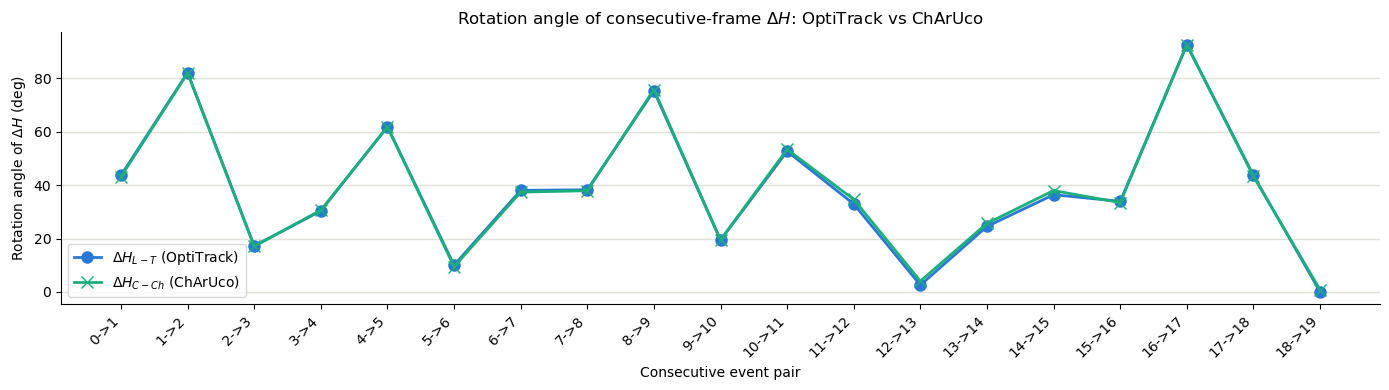

In [16]:
fig, ax = plt.subplots(figsize=(14, 4))

x = np.arange(len(comparison_df))
# .to_numpy() avoids a pandas/matplotlib multi-dimensional-indexing
# incompatibility (see the note on the Sync_Data/User_Marker plot above).
ax.plot(x, comparison_df["angle_L_T_deg"].to_numpy(), color="#2a78d6", linewidth=2,
        marker="o", markersize=8, label=r"$\Delta H_{L-T}$ (OptiTrack)")
ax.plot(x, comparison_df["angle_C_Ch_deg"].to_numpy(), color="#1baf7a", linewidth=2,
       marker="x", markersize=8, label=r"$\Delta H_{C-Ch}$ (ChArUco)")

ax.set_xticks(x)
ax.set_xticklabels(comparison_df["event_pair"].to_numpy(), rotation=45, ha="right")
ax.set_xlabel("Consecutive event pair")
ax.set_ylabel("Rotation angle of $\\Delta H$ (deg)")
ax.set_title("Rotation angle of consecutive-frame $\\Delta H$: OptiTrack vs ChArUco")
ax.grid(axis="y", color="#e1e0d9", linewidth=1)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()

In [13]:
def rotation_geodesic_deg(H1, H2):
    """Full SO(3) angular distance between two rotations - the angle of the
    error rotation R1^T @ R2. Unlike comparing rotation_angle_deg(H1) against
    rotation_angle_deg(H2) independently, this is sensitive to axis
    misalignment too: two deltas can have identical rotation magnitude while
    rotating about completely different axes, and only this metric catches
    that.
    """
    R_err = H1[:3, :3].T @ H2[:3, :3]
    return np.degrees(Rotation.from_matrix(R_err).magnitude())


full_rotation_comparison_df = pd.DataFrame({
    "event_pair": [f"{i}->{i + 1}" for i in range(len(dH_L_T))],
    "angle_L_T_deg": comparison_df["angle_L_T_deg"],
    "angle_C_Ch_deg": comparison_df["angle_C_Ch_deg"],
    "rotation_geodesic_diff_deg": [rotation_geodesic_deg(h1, h2) for h1, h2 in zip(dH_L_T, dH_C_Ch)],
})

print(f"Mean full-rotation geodesic diff: {full_rotation_comparison_df['rotation_geodesic_diff_deg'].mean():.3f} deg")
print(f"Max  full-rotation geodesic diff: {full_rotation_comparison_df['rotation_geodesic_diff_deg'].max():.3f} deg")

full_rotation_comparison_df

Mean full-rotation geodesic diff: 1.566 deg
Max  full-rotation geodesic diff: 2.660 deg


,event_pair,angle_L_T_deg,angle_C_Ch_deg,rotation_geodesic_diff_deg
0,0->1,43.652825,43.142298,2.659927
1,1->2,82.101178,81.912809,1.377603
2,2->3,17.248022,17.070815,1.515022
3,3->4,30.337568,30.616775,0.772490
4,4->5,61.869846,61.769856,0.138893
5,5->6,10.040494,9.473508,1.227563
6,6->7,38.031249,37.380340,1.070049
7,7->8,38.247111,37.890096,2.109059
8,8->9,75.241460,75.755445,2.568985
9,9->10,19.389385,19.532032,1.352506


In [14]:
def translation_norm_m(H):
    return np.linalg.norm(H[:3, 3])


# Unlike rotation angle, translation magnitude is NOT invariant under the
# fixed LinkCamera<->Camera / TableMarker<->ChArUco offsets: if either mount
# has a nonzero translational arm, rotating about it adds a lever-arm
# translation component on top of the "true" shared translation, and that
# lever-arm term scales with how much the pair rotates. So don't expect
# translation_L_T_m and translation_C_Ch_m to match as tightly as the
# rotation angles did, especially for the larger-rotation event pairs.
translation_comparison_df = pd.DataFrame({
    "event_pair": [f"{i}->{i + 1}" for i in range(len(dH_L_T))],
    "translation_L_T_m": [translation_norm_m(h) for h in dH_L_T],
    "translation_C_Ch_m": [translation_norm_m(h) for h in dH_C_Ch],
})
translation_comparison_df["translation_diff_m"] = (
    translation_comparison_df["translation_L_T_m"] - translation_comparison_df["translation_C_Ch_m"]
).abs()

print(f"Mean |translation_L_T - translation_C_Ch|: {translation_comparison_df['translation_diff_m'].mean():.4f} m")
print(f"Max  |translation_L_T - translation_C_Ch|: {translation_comparison_df['translation_diff_m'].max():.4f} m")

translation_comparison_df

Mean |translation_L_T - translation_C_Ch|: 0.0100 m
Max  |translation_L_T - translation_C_Ch|: 0.0340 m


,event_pair,translation_L_T_m,translation_C_Ch_m,translation_diff_m
0,0->1,0.099147,0.115195,0.016048
1,1->2,0.165881,0.199904,0.034023
2,2->3,0.172286,0.172412,0.000126
3,3->4,0.023678,0.027116,0.003438
4,4->5,0.242595,0.229815,0.012780
5,5->6,0.218534,0.229517,0.010983
6,6->7,0.076178,0.052897,0.023281
7,7->8,0.038521,0.043059,0.004537
8,8->9,0.095301,0.092765,0.002536
9,9->10,0.115075,0.107275,0.007800


In [15]:
xyz_comparison_df = pd.DataFrame({
    "event_pair": [f"{i}->{i+1}" for i in range(len(dH_L_T))],

    "dx_L_T_mm": [1000 * H[0, 3] for H in dH_L_T],
    "dy_L_T_mm": [1000 * H[1, 3] for H in dH_L_T],
    "dz_L_T_mm": [1000 * H[2, 3] for H in dH_L_T],

    "dx_C_Ch_mm": [1000 * H[0, 3] for H in dH_C_Ch],
    "dy_C_Ch_mm": [1000 * H[1, 3] for H in dH_C_Ch],
    "dz_C_Ch_mm": [1000 * H[2, 3] for H in dH_C_Ch],
})

xyz_comparison_df["dx_diff_mm"] = (
    xyz_comparison_df["dx_L_T_mm"] -
    xyz_comparison_df["dx_C_Ch_mm"]
)

xyz_comparison_df["dy_diff_mm"] = (
    xyz_comparison_df["dy_L_T_mm"] -
    xyz_comparison_df["dy_C_Ch_mm"]
)

xyz_comparison_df["dz_diff_mm"] = (
    xyz_comparison_df["dz_L_T_mm"] -
    xyz_comparison_df["dz_C_Ch_mm"]
)

xyz_comparison_df

,event_pair,dx_L_T_mm,dy_L_T_mm,dz_L_T_mm,dx_C_Ch_mm,dy_C_Ch_mm,dz_C_Ch_mm,dx_diff_mm,dy_diff_mm,dz_diff_mm
0,0->1,4.855750,-96.831559,-20.738837,-6.962973,-112.596754,-23.309005,11.818724,15.765195,2.570169
1,1->2,-78.830562,106.643723,-99.646056,-92.328413,121.223359,-129.390351,13.497851,-14.579636,29.744295
2,2->3,75.621235,-148.881581,-42.403594,67.391774,-152.171780,-45.032753,8.229460,3.290199,2.629159
3,3->4,-2.871528,-16.465321,-16.772173,-8.934874,-12.201029,-22.507804,6.063346,-4.264291,5.735632
4,4->5,-153.054008,90.157471,-165.221700,-144.991459,60.087186,-167.874769,-8.062549,30.070285,2.653069
5,5->6,-11.121911,157.076786,151.526155,-16.137657,163.705418,160.057071,5.015745,-6.628632,-8.530916
6,6->7,45.117217,22.608106,57.065335,32.985467,26.505704,31.741171,12.131750,-3.897598,25.324164
7,7->8,-13.391096,-28.553157,-22.119441,-17.177726,-36.221057,-15.716278,3.786630,7.667900,-6.403163
8,8->9,64.029306,-4.703369,70.430349,70.778063,-2.955555,59.892637,-6.748757,-1.747813,10.537712
9,9->10,-59.357524,19.586951,-96.619222,-63.755301,8.800593,-85.823276,4.397778,10.786358,-10.795946
